# 08 — K Nearest Neighbors: optimized HRI regression

**Purpose:** Tune K Nearest Neighbors on the frozen `train.csv` and report grouped cross-validation and frozen `validation.csv` performance. Each year of a `cell_id` stays in the same CV fold. All training and evaluation code is in this notebook.

**Research limit:** `hri_score_0_100` is a constructed same-year index. Better scores show a better approximation of that index, not a forecast of future habitat degradation. The nine inputs match the original notebooks. Keep the test cell locked until one model is selected across all ten notebooks.

## 1 — Imports, paths, target, and predictors

In [4]:
from pathlib import Path
import json
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, ParameterGrid, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor

# Find the component root from any working directory inside the repository.
PROJECT_ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                     if (p / 'data/splits/hri/model_v1/train.csv').is_file()), None)
if PROJECT_ROOT is None:
    PROJECT_ROOT = next((p / 'components/habitat_risk' for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                         if (p / 'components/habitat_risk/data/splits/hri/model_v1/train.csv').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Run Jupyter from within the repository or component directory.')
DATA_DIR = PROJECT_ROOT / 'data/splits/hri/model_v1'
OUTPUT_DIR = PROJECT_ROOT / 'artifacts/hri/model_training_optimized/knn'
TARGET = 'hri_score_0_100'
FEATURES = [
    'climate__annual_mean_temperature_c',
    'climate__annual_precipitation_mm',
    'climate__temperature_c_anomaly',
    'climate__temperature_c_trailing5_slope_per_year',
    'climate__precipitation_mm_anomaly',
    'climate__precipitation_mm_trailing5_slope_per_year',
    'terrain__mean_elevation_m',
    'terrain__elevation_sd_m',
    'terrain__mean_slope_degrees',
]
RANDOM_STATE = 42


## 2 — Load and audit the frozen training and validation splits

In [5]:
def load_split(name):
    frame = pd.read_csv(DATA_DIR / f'{name}.csv')
    required = set(FEATURES + [TARGET, 'cell_id', 'reference_year', 'dataset_split'])
    missing = required.difference(frame.columns)
    if missing:
        raise ValueError(f'{name} missing columns: {sorted(missing)}')
    if not frame['dataset_split'].eq(name).all():
        raise ValueError(f'{name}: incorrect dataset_split labels')
    if frame[['cell_id', 'reference_year']].duplicated().any():
        raise ValueError(f'{name}: duplicate cell-year keys')
    for col in FEATURES + [TARGET]:
        frame[col] = pd.to_numeric(frame[col], errors='coerce')
    frame[FEATURES] = frame[FEATURES].replace([np.inf, -np.inf], np.nan)
    valid = np.isfinite(frame[TARGET].to_numpy(dtype=float))
    if not valid.all():
        print(f'{name}: dropping {(~valid).sum()} rows with invalid target')
        frame = frame.loc[valid].copy()
    if frame.empty:
        raise ValueError(f'{name}: no usable rows')
    return frame

train = load_split('train')
validation = load_split('validation')
if set(train.cell_id) & set(validation.cell_id):
    raise ValueError('A cell_id occurs in both training and validation')
for label, frame in [('train', train), ('validation', validation)]:
    print(label, frame.shape, 'cells:', frame.cell_id.nunique(),
          'missing feature values:', int(frame[FEATURES].isna().sum().sum()))
display(train[FEATURES + [TARGET]].describe().T)


train (24752, 33) cells: 1768 missing feature values: 0
validation (5306, 33) cells: 379 missing feature values: 0


,count,mean,std,min,25%,50%,75%,max
climate__annual_mean_temperature_c,24752.0,0.775281,0.156236,0.000000,0.746875,0.823085,0.869670,1.000000
climate__annual_precipitation_mm,24752.0,0.240596,0.157357,0.000000,0.129947,0.202946,0.306998,1.000000
climate__temperature_c_anomaly,24752.0,0.480155,0.128072,0.000000,0.447461,0.480505,0.513489,1.000000
climate__temperature_c_trailing5_slope_per_year,24752.0,0.437624,0.142639,0.000000,0.394487,0.429949,0.477683,1.000000
climate__precipitation_mm_anomaly,24752.0,0.530328,0.133278,0.000000,0.490716,0.527164,0.562523,1.000000
climate__precipitation_mm_trailing5_slope_per_year,24752.0,0.527070,0.107267,0.000000,0.491472,0.524089,0.560961,1.000000
terrain__mean_elevation_m,24752.0,0.086294,0.144994,0.000000,0.017779,0.037951,0.072093,1.000000
terrain__elevation_sd_m,24752.0,0.101708,0.155323,0.000000,0.014867,0.025690,0.123512,1.000000
terrain__mean_slope_degrees,24752.0,0.171137,0.209810,0.000000,0.031550,0.059662,0.247864,1.000000
hri_score_0_100,24752.0,37.042325,14.326639,0.793036,27.360073,35.769426,44.626012,93.502631


## 3 — Define the preprocessing pipeline and parameter search

In [6]:
# Imputation and standardization are fitted inside each CV training fold.
preprocess = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

regressor = KNeighborsRegressor(n_jobs=4)
param_space = {
    'model__n_neighbors': [10, 25, 50, 100],
    'model__weights': ['uniform', 'distance'],
    'model__p': [1, 2],
}

pipeline = Pipeline([('preprocess', preprocess), ('model', regressor)])

## 4 — Grouped cross-validation and hyperparameter optimization

Search uses only `train.csv`. Mean CV MAE chooses the parameters; each fold fits its own preprocessing. Increase `N_ITER` for a wider search, consistently across models.

In [7]:
N_FOLDS = 3
N_ITER = 8
if N_FOLDS < 2 or N_FOLDS > train.cell_id.nunique():
    raise ValueError('N_FOLDS must be between 2 and the number of training cells')
cv = GroupKFold(n_splits=N_FOLDS)
search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_space,
    n_iter=min(N_ITER, len(ParameterGrid(param_space))),
    scoring={'MAE': 'neg_mean_absolute_error',
             'RMSE': 'neg_root_mean_squared_error', 'R2': 'r2'},
    refit='MAE', cv=cv, n_jobs=1, random_state=RANDOM_STATE,
    return_train_score=True, error_score='raise', verbose=1,
)
start = time.perf_counter()
search.fit(train[FEATURES], train[TARGET], groups=train.cell_id)
train_seconds = time.perf_counter() - start
model = search.best_estimator_  # Refitted on all training rows only.
print('Best CV MAE:', -search.best_score_)
print('Best parameters:', search.best_params_)
print('Tuning seconds:', round(train_seconds, 2))


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best CV MAE: 7.327832403064554
Best parameters: {'model__weights': 'distance', 'model__p': 1, 'model__n_neighbors': 10}
Tuning seconds: 7.38


## 5 — Training and held-out validation diagnostics

In [8]:
def score(y, prediction):
    return {'MAE': float(mean_absolute_error(y, prediction)),
            'RMSE': float(np.sqrt(mean_squared_error(y, prediction))),
            'R2': float(r2_score(y, prediction))}

train_pred = model.predict(train[FEATURES])
val_pred = model.predict(validation[FEATURES])
train_metrics = score(train[TARGET], train_pred)
val_metrics = score(validation[TARGET], val_pred)
baseline = DummyRegressor(strategy='mean').fit(train[FEATURES], train[TARGET])
baseline_metrics = score(validation[TARGET], baseline.predict(validation[FEATURES]))
best = search.best_index_
summary = {
    'model': 'knn', 'n_train': len(train), 'n_validation': len(validation),
    'folds': N_FOLDS, 'candidates': len(search.cv_results_['params']),
    'cv_MAE': float(-search.cv_results_['mean_test_MAE'][best]),
    'cv_MAE_std': float(search.cv_results_['std_test_MAE'][best]),
    'cv_RMSE': float(-search.cv_results_['mean_test_RMSE'][best]),
    'cv_R2': float(search.cv_results_['mean_test_R2'][best]),
    'cv_train_MAE': float(-search.cv_results_['mean_train_MAE'][best]),
    'train_MAE': train_metrics['MAE'],
    'validation_MAE': val_metrics['MAE'],
    'validation_RMSE': val_metrics['RMSE'],
    'validation_R2': val_metrics['R2'],
    'baseline_validation_MAE': baseline_metrics['MAE'],
    'train_validation_MAE_gap': val_metrics['MAE'] - train_metrics['MAE'],
    'tuning_seconds': train_seconds,
}
display(pd.DataFrame([summary]))
print('Large positive gap suggests overfitting; high train and validation MAE suggests underfitting.')
print('Compare validation MAE with the baseline and other models before choosing a winner.')


,model,n_train,n_validation,folds,candidates,cv_MAE,cv_MAE_std,cv_RMSE,cv_R2,cv_train_MAE,train_MAE,validation_MAE,validation_RMSE,validation_R2,baseline_validation_MAE,train_validation_MAE_gap,tuning_seconds
0,knn,24752,5306,3,8,7.327832,0.141195,10.565202,0.455342,0.265608,0.281452,6.662271,9.956032,0.456118,10.5042,6.38082,7.383822


Large positive gap suggests overfitting; high train and validation MAE suggests underfitting.
Compare validation MAE with the baseline and other models before choosing a winner.


## 6 — Save CV results, fitted model, and validation predictions

In [9]:
if (OUTPUT_DIR / 'final_test_metrics.csv').exists():
    raise FileExistsError('Final test has already been evaluated; preserve that result.')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
pd.DataFrame(search.cv_results_).to_csv(OUTPUT_DIR / 'cv_results.csv', index=False)
pd.DataFrame([summary]).to_csv(OUTPUT_DIR / 'metrics.csv', index=False)
(OUTPUT_DIR / 'best_params.json').write_text(json.dumps(search.best_params_, indent=2))
predictions = validation[['cell_id', 'reference_year', TARGET]].copy()
predictions['prediction'] = val_pred
predictions['residual'] = predictions[TARGET] - predictions['prediction']
predictions.to_csv(OUTPUT_DIR / 'validation_predictions.csv', index=False)
if 'fixed_risk_class' in validation:
    predictions['fixed_risk_class'] = validation['fixed_risk_class'].to_numpy()
    predictions['absolute_error'] = predictions['residual'].abs()
    risk_errors = predictions.groupby('fixed_risk_class', dropna=False).agg(
        n=(TARGET, 'size'), MAE=('absolute_error', 'mean'),
        mean_residual=('residual', 'mean'))
    risk_errors.to_csv(OUTPUT_DIR / 'validation_by_risk_class.csv')
    display(risk_errors)
joblib.dump(model, OUTPUT_DIR / 'model.joblib')
print('Saved results to', OUTPUT_DIR)


,n,MAE,mean_residual
fixed_risk_class,,,
High,146,20.489159,20.232524
Low,2434,6.497912,-5.071391
Moderate,2726,6.068480,2.625944


Saved results to /Users/keerthikeerthi/Desktop/J26-IT-359/components/habitat_risk/artifacts/hri/model_training_optimized/knn


## 7 — Inspect errors and candidate rankings

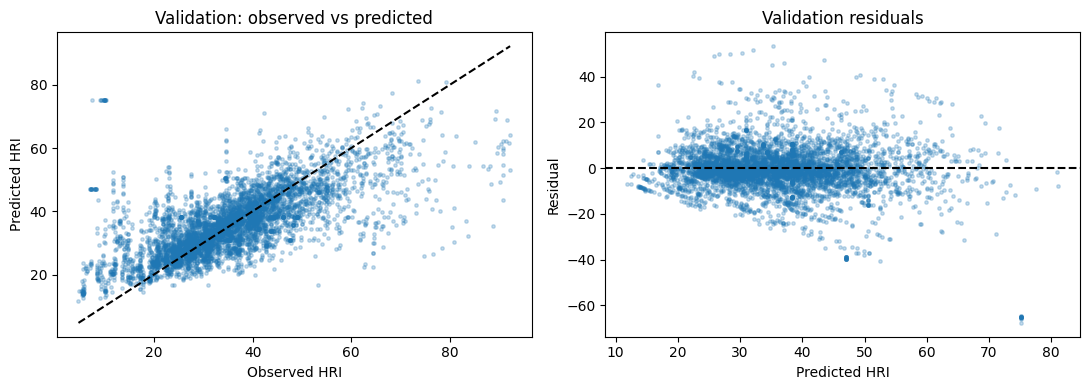

,rank_test_MAE,mean_test_MAE,std_test_MAE,mean_train_MAE,mean_test_RMSE,mean_test_R2,params
1,1,-7.327832,0.141195,-0.265608,-10.565202,0.455342,"{'model__weights': 'distance', 'model__p': 1, ..."
2,2,-7.608727,0.138842,-0.249446,-10.799036,0.431283,"{'model__weights': 'distance', 'model__p': 1, ..."
0,3,-7.711041,0.160270,-6.336667,-11.026053,0.406904,"{'model__weights': 'uniform', 'model__p': 1, '..."
7,4,-7.964046,0.182960,-0.249738,-11.184003,0.390132,"{'model__weights': 'distance', 'model__p': 1, ..."
5,5,-8.006318,0.156274,-0.249738,-11.243039,0.383586,"{'model__weights': 'distance', 'model__p': 2, ..."
4,6,-8.354220,0.234731,-0.252450,-11.603864,0.343523,"{'model__weights': 'distance', 'model__p': 1, ..."
6,7,-8.485720,0.220165,-8.164519,-11.816071,0.319272,"{'model__weights': 'uniform', 'model__p': 1, '..."
3,8,-8.909023,0.260279,-8.746282,-12.293008,0.263188,"{'model__weights': 'uniform', 'model__p': 2, '..."


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(validation[TARGET], val_pred, s=6, alpha=0.25)
lo = min(validation[TARGET].min(), val_pred.min())
hi = max(validation[TARGET].max(), val_pred.max())
axes[0].plot([lo, hi], [lo, hi], 'k--')
axes[0].set(xlabel='Observed HRI', ylabel='Predicted HRI', title='Validation: observed vs predicted')
axes[1].scatter(val_pred, validation[TARGET] - val_pred, s=6, alpha=0.25)
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set(xlabel='Predicted HRI', ylabel='Residual', title='Validation residuals')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'validation_diagnostics.png', dpi=160)
plt.show()

# Inspect the search ranking and fold variation; training results are diagnostic only.
columns = ['rank_test_MAE', 'mean_test_MAE', 'std_test_MAE',
           'mean_train_MAE', 'mean_test_RMSE', 'mean_test_R2', 'params']
display(pd.DataFrame(search.cv_results_)[columns].sort_values('rank_test_MAE').head(10))


## 8 — Final test (locked)

Run once on only the selected model after comparing all ten validation results. Do not revise the model after viewing the test result.

In [11]:
# Run this cell once, only after selecting ONE model using cross-validation and validation.
RUN_FINAL_TEST = False
if not RUN_FINAL_TEST:
    print('Final test is locked. Set RUN_FINAL_TEST=True only for your selected model.')
else:
    if (OUTPUT_DIR / 'final_test_metrics.csv').exists():
        raise FileExistsError('Final test was already evaluated for this model.')
    test = load_split('test')
    if set(test.cell_id) & (set(train.cell_id) | set(validation.cell_id)):
        raise ValueError('A cell_id occurs in multiple frozen splits')
    test_pred = model.predict(test[FEATURES])
    test_metrics = {'model': 'knn', 'split': 'test', 'n': len(test),
                    **score(test[TARGET], test_pred)}
    pd.DataFrame([test_metrics]).to_csv(OUTPUT_DIR / 'final_test_metrics.csv', index=False)
    test_predictions = test[['cell_id', 'reference_year', TARGET]].copy()
    test_predictions['prediction'] = test_pred
    test_predictions.to_csv(OUTPUT_DIR / 'final_test_predictions.csv', index=False)
    display(pd.DataFrame([test_metrics]))


Final test is locked. Set RUN_FINAL_TEST=True only for your selected model.
